In [4]:
#imports
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import comb
from scipy.stats import mode
from sklearn.datasets import make_moons, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier,ExtraTreesClassifier
from sklearn.metrics import accuracy_score
from sklearn.inspection import permutation_importance
import time


ValueError: x and y must have same first dimension, but have shapes (200,) and (0,)

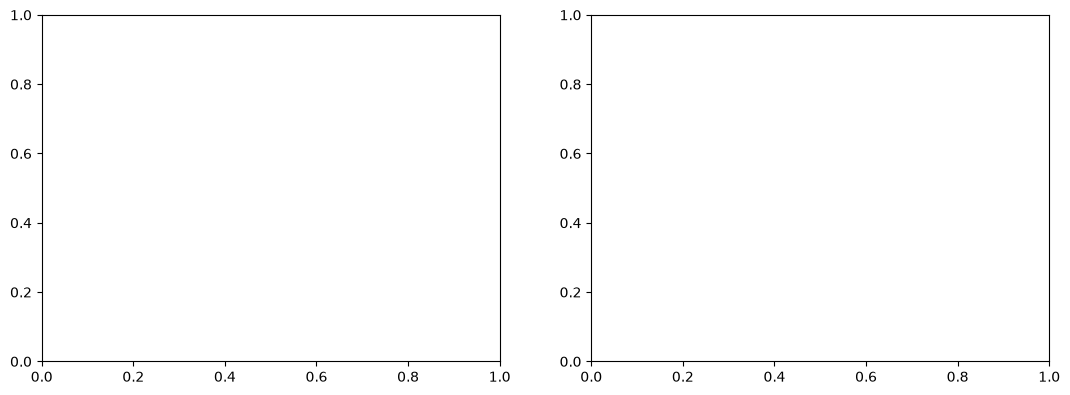

In [5]:
def prob_condorcet(B, p):
    min_votos = (B // 2) + 1
    return sum(comb(B, k) * (p ** k) * (1.0 - p) ** (B -k) for k in range(min_votos, B + 1))

p_vals = np.linspace(0.01, 0.99, 200)
fig, axes = plt.subplots(1, 2 ,figsize=(13, 4.5))
curva_maj = [] #CURVA_MAJ VAI TOMAR NO CU CARALHO
cor = [] # VAI SE FUDE NESSE CARALHO TBM PORRA MERDA FILHA DA PUTA
axes[0].plot(p_vals, curva_maj, color=cor, linewidth=2, label='B=1 (ou Clones Correlacionados)')
for B_tam, cor in [(3, 'steelblue'), (11, 'seagreen'), (101, 'crimson')]:
    curva_maj = [prob_condorcet(B_tam, p) for p in p_vals]
    axes[0].plot(p_vals, curva_maj, color=cor, linewidth= f'Comite Independente(B(B_tam))')
axes[0].scatter([0.70], [prob_condorcet(3, 0.70)], color='black', zorder=5,s=50)
axes[0].annotate("p=0.70 -> Maj=78.4%", xy=(0.70, 0.784), xytext=(0.42, 0.85),
                    arrowprops=dict(arowstyle="->", lw=1.2), fontweight='bold',
                    fontsize=9)
axes[0].set_title("Teorema do juri de condorcet: ", fontweight='bold')
axes[0].set_xlabel("Acuracia individual (p)")
axes[0].set_ylabel("Probabilidade de acerto do comite ($P_{maj}$)")
axes[0].set_xlabel(loc='lower right', fontsize=8)
axes[0].grid(True, linestyle="--",alpha=0.6)

u_vals = np.linespace(-3.0, 4.5, 200)
u1, u2 = 4.0, -2.0
media_quadrados = (u1**2 + u2**2)
erro_medio = (u1 + u2) / 2.0
quadrado_media = erro_medio ** 2
axes[1].plot(u_vals, u_vals**2, color= 'navy', linewidth=2, 
             label = "Perda Convexa $g(u) = u^S2") # seila que porra é isso
axes[1].plot([u2, u1], [u2**2, u1**2], color='navy', linewidth=2, 
             label='Corda Scante ,sei la que pora isso significa: ')
axes[1].scatter([erro_medio], [quadrado_media], color='forestgreen',
                s=70, zorder=6, label=f'EWrro DO Ensemble> $(E[u])^2 = {quadrado_media:.1f}$')
axes[1].annotate("Reducao de MSE\n(Ganho de Jensen)", xy=(erro_medio, quadrado_media + 0.5), xytext=(1.6, 5.5),
                            arrowproops=dict(arrowstyle="->", color='darkorange', lw=2), fontweight='bold', fontsize=9)
axes[1].set_title("Desigualdade entre Jensen no Baggin",fontweight='bold')
axes.set_xlabel("Erro de predição( 4u = y - \\hat{f}$)")
axes[1].set_ylabel("Erro quadratico: ($u^2$)")
axes[1].grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
class BagginClassifierNumpy:
    def __init__(self, n_estimators=100, voting='hard', random_state=42):
        self.n_estimators = n_estimators
        self.voting = voting
        self.random_state = random_state
        self.estimators_ = []
        self.oob_indices_ = []
    def fit(self, X, y):
        np.random.seed(self.random_state)
        N = X.shape[0]
        self.estimators_ = []
        for b in range(self.n_estimators):
            boot_idx = np.random.choice(N, size=N, replace=True)
            oob_idx = np.setdiff1d(np.arange(N), boot_idx)
            tree = DecisionTreeClassifier(random_state=self.random_state + b)
            tree.fit(X[boot_idx], y[boot_idx])
            self.estimators_.append(tree)
            self.oob_indices_.append(oob_idx)
        return self
    def predict_proba(self, X):
        if self.voting == 'soft':
            return np.argmax(self.predict_proba(X), axis=1)
        preds = np.array([tree.predicrt(X) for tree in self.estimators_])
        return mode(preds, axis=0, keepdims=False).mode

    provas_slides15 = np.array([[0.01, 0.99],[0.55, 0.45],[0.55, 0.45]])
    voto_hard_s15 = mode(np.argmax(provas_slides15, axis=1),keepdims=False).mode
    voto_softOs15 = np.argmax(np.mean(provas_slides15, axis=0))

    print("=== HARD vs SOFT VOTING ===")
    print(f"Votos discretos das 3 avres: {np.argmax(provas_slides15,axis=1)} Decisao Hard Voting: Classe {voto_hard_s15}")


X_moons ,Y_moons = make_moons(n_samples=400, noise=0.5, random_state=42)
X_m_tr, X_m_te, Y_m_tr, Y_m_te = train_test_split(X_moons, Y_moons,test_size=3, random_state=42)
avre_unica = DecisionTreeClassifier(random_state=42).fit(X_m_tr, Y_m_tr,test_size=3,random_state=42)
bag_moons = BagginClassifierNumpy(n_estimators=100, voting='soft',random_state=42).fit(X_m_tr,Y_m_tr)
fig, axes = plt.subplots(1, 3,figsize=(15,4.2))
N_finitos = np.arange(2, 101)
p_oob_ixato = (1.0 - 1.0 / N_finitos) ** N_finitos * 100.0
axes[0].plot(N_finitos, p_oob_ixato, color='navy', linewidth=2, label=3)
axes[0].axhline((1.0 / np.e) * 100.0, color='crimson', linestyle='--',
                linewidth=2, label='Limite $1/e \\aprox 36.79\\%$')
axes[0].scatter([2,5,10], [(1 - 1/n)**n  * 100 for n in [2,5,10]],
                color='darkorange',zorder=5, s=46)
axes[0].set_title("Convergencia 00B p/ N Finito", fontweight='bold')
axes[0].set_xlabel("Tamanho do Dataset (N)")
axes[0].set_ylabel("% dessas porra de amostra out-of-bag")
axes[0].set_legend(loc='lower right' ,fontsize=8)
axes[0].grid(True, linestyle='--', alpha=0.5)

xx, yy = np.meshgrid(np.linspace(X_moons[: , 0].min()- 0.5, X_moons[:, 0].
                                 max() + 0.5, 180)),
np.linspace(X_moons[:, 1].min() -0.5, X_moons[:, 0].
            max() + 0.5 ,180)
malha = np.c_[xx.ravel(), yy.ravel()]
axes[1].contourf(xx,yy, avre_unica.predict(malha).reshape(xx.shape), alpha=0.3, cmap='coolwarm')
axes[1].scatter(X_m_te[:, 0], X_m_te[: , 1], c=Y_m_te,cmap='coolwarm',edgecolors='k',s=25)
axes[1].set_title(f"(a) 1. Avre profunda de alta variancia \nAcc teste:{accuracy_score(Y_m_te, avre_unica.predict(X_m_te)):.4f}", fontweight='bold')
axes[1].set_xlabel("$X_1$")
axes[1].set_ylabel("$X_2$")
axes[2].contourf(xx, yy,bag_moons.predict(malha).reshape(xx.shape), alpha=0.3, cmap='coolwarm')
axes[2].scatter(X_m_te[:, 0], X_m_te[:, 1], c=Y_m_te, cmap='coolwarm',edgecolors='k',s=25)
axes[2].set_title(f"(b) Ensemble Bagging (fronteira suave)\n ACC: {accuracy_score(Y_m_te,bag_moons.predict(X_m_te)):.4f}",fontweight='bold')
axes[2].set_xlabel("$X_1$")
axes[2].set_ylabel("$X_2$")
plt.tight_layout()
plt.show()


In [ ]:
cancer = load_breast_cancer()
X_tr,X_te, Y_tr,Y_te =  train_test_split(cancer.data, cancer.target, test_size=0.30, random_state=42,stratify=cancer.target)
modalidades_slide13 = {
    "1. Bagging\n(Reposicao, 100% COL): " BaggingClassifier(n_estimators=100, bootstrap=True,max_samples=1.0, max_features=1.0,random_state=42, n_jobs=-1),
    "2. Pasting\n(Sem.Rep., 80% Lin):" BaggingClassifier(n_estimators=100,bootstrap=False,max_samples=0.8,max_features=1.0,random_state=42, n_jobs=-1),
   "3. Random Subspaces\n(100% Lin, 50% col):" BaggingClassifier(n_estimators=100, bootstrap=False,max_samples=1.0, max_features=0.5,random_state=42,n_jobs=-1),
    "4. Random Patches\n(Reposicao, 50% Col):" BaggingClassifier(n_estimators=100, bootstrap=True, max_samples=1.0,max_features=0.5,random_state=42,n_jobs=-1)
}
nomes_mod, accs_mod = [], []
for nome, mod in modalidades_slide13.items():
    mod.fit(X_tr, Y_tr)
    nomes_mod.append(nome)
    acc_mod.append(accuracy_score(Y_te, mod.predict(X_te)))
plt.figure(figsize=(9, 3.8))
barras_mod = plt.bar(nomes_mod, accs_mod, color=['steelblue','slategray', 'darkcyan', 'teal'], width=0.45)
plt.ylim(0.90, 0.98)
plt.title("Comparativo dos 4 bagulhos de amostragem: ", fontweight='bold')
plt.ylabel("Acuracia dessa porra de teste: ")
for b in barras_mod:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width() /2., h + 0.002. f"{j:.4f}", ha='center', fontweight='bold')
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

In [ ]:
def calcula_correlacao_media_avre()